# Task 2 (Easy): Content Type Analysis Dashboard
**Auspify Technologies | Data Analysis Using Python Internship**
**Intern:** Aarti Jamage

**Goal:** Analyze the distribution of Movies and TV Shows available on Netflix.

**Workflow:** 1) Load cleaned data → 2) Count Movies and TV Shows → 3) Visualize distribution → 4) Compare proportions → 5) Summarize findings

## Step 1: Load the cleaned dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")
os.makedirs("../outputs/charts", exist_ok=True)

df = pd.read_csv("../data/netflix_cleaned.csv")
print("Shape:", df.shape)
df.head()

Shape: (8787, 15)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year_added,month_added,duration_value,duration_unit,rating_group
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,September,90,min,Teens
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,September,1,Season,Adults
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,September,1,Season,Adults
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,September,91,min,Teens
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,September,125,min,Adults


## Step 2: Calculate the total number of Movies and TV Shows

In [2]:
counts = df["type"].value_counts()
percent = df["type"].value_counts(normalize=True).mul(100).round(1)

summary = pd.DataFrame({"Count": counts, "Percentage (%)": percent})
print("Total titles:", len(df))
summary

Total titles: 8787


,Count,Percentage (%)
type,,
Movie,6124,69.7
TV Show,2663,30.3


## Step 3: Create visualizations for content distribution

### 3a. Bar chart: number of titles by type

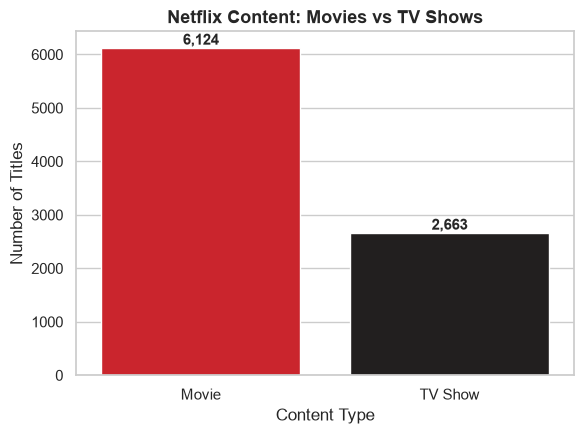

In [3]:
colors = {"Movie": "#E50914", "TV Show": "#221F1F"}

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.countplot(data=df, x="type", order=counts.index, palette=colors, hue="type", legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_title("Netflix Content: Movies vs TV Shows", fontsize=13, fontweight="bold")
ax.set_xlabel("Content Type")
ax.set_ylabel("Number of Titles")
plt.tight_layout()
plt.savefig("../outputs/charts/task2_type_countplot.png", dpi=300, bbox_inches="tight")
plt.show()

### 3b. Donut chart: share of each type

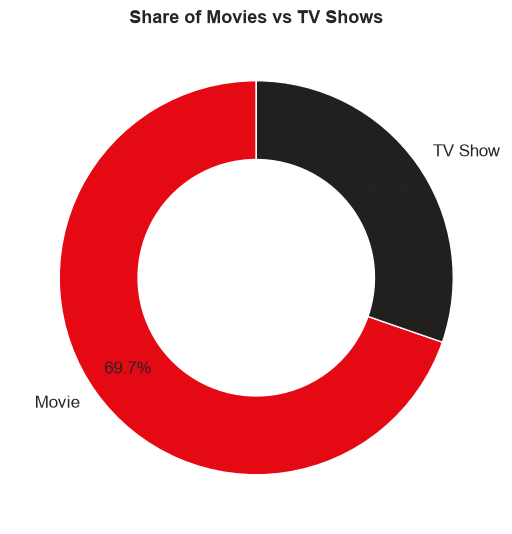

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
       colors=[colors[t] for t in counts.index], wedgeprops=dict(width=0.4, edgecolor="white"),
       textprops={"fontsize": 12}, pctdistance=0.8)
ax.set_title("Share of Movies vs TV Shows", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../outputs/charts/task2_type_donut.png", dpi=300, bbox_inches="tight")
plt.show()

### 3c. Content type over time (by release year, 2000 onwards)

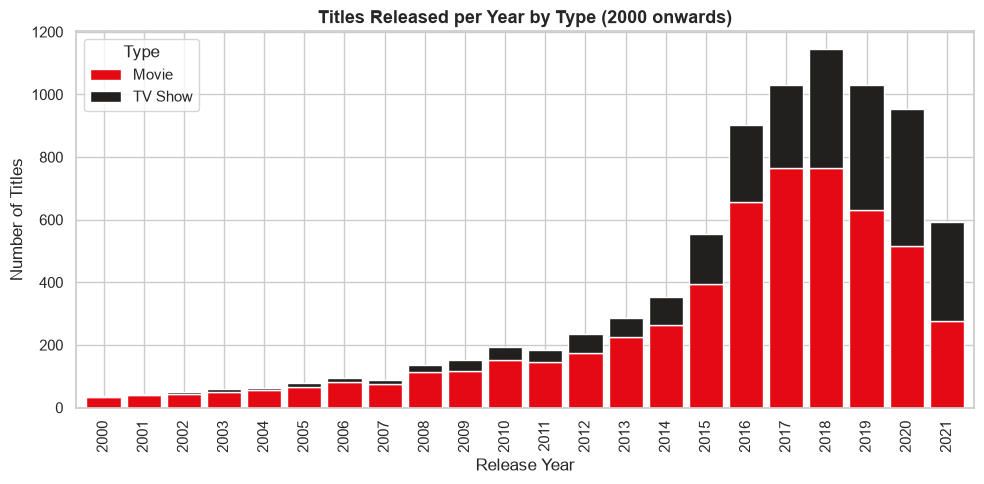

In [5]:
recent = df[df["release_year"] >= 2000]
yearly = recent.groupby(["release_year", "type"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
yearly.plot(kind="bar", stacked=True, color=[colors[c] for c in yearly.columns], ax=ax, width=0.85)
ax.set_title("Titles Released per Year by Type (2000 onwards)", fontsize=13, fontweight="bold")
ax.set_xlabel("Release Year")
ax.set_ylabel("Number of Titles")
ax.legend(title="Type")
plt.tight_layout()
plt.savefig("../outputs/charts/task2_type_by_release_year.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 4: Compare content proportions

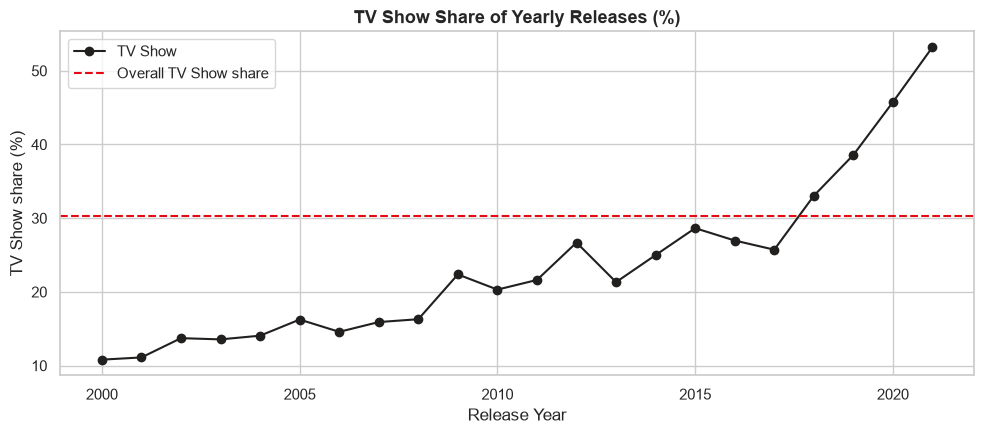

In [6]:
# Proportion of Movies vs TV Shows within each release year
share = yearly.div(yearly.sum(axis=1), axis=0).mul(100)

fig, ax = plt.subplots(figsize=(10, 4.5))
share["TV Show"].plot(marker="o", color=colors["TV Show"], ax=ax)
ax.set_title("TV Show Share of Yearly Releases (%)", fontsize=13, fontweight="bold")
ax.set_xlabel("Release Year")
ax.set_ylabel("TV Show share (%)")
ax.axhline(df["type"].eq("TV Show").mean() * 100, color="#E50914", linestyle="--", label="Overall TV Show share")
ax.legend()
plt.tight_layout()
plt.savefig("../outputs/charts/task2_tvshow_share_trend.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
# Audience mix and length by type
print("Median length: Movie =", df.loc[df.type == "Movie", "duration_value"].median(), "min | TV Show =",
      df.loc[df.type == "TV Show", "duration_value"].median(), "season(s)")
print("\nAudience group split within each type (%):")
(pd.crosstab(df["type"], df["rating_group"], normalize="index") * 100).round(1)

Median length: Movie = 98.0 min | TV Show = 1.0 season(s)

Audience group split within each type (%):


rating_group,Adults,Kids,Teens,Unrated
type,,,,
Movie,46.7,7.2,44.8,1.3
TV Show,43.0,17.4,39.4,0.2


## Step 5: Key findings

1. **Movies dominate the catalogue.** There are 6,124 Movies (69.7%) against 2,663 TV Shows (30.3%), about 2.3 movies for every TV show.
2. **TV Shows are catching up.** Their share of yearly releases rises steadily from the mid-2010s, and in 2021 TV Shows (315) outnumber Movies (277) for the first time in the release-year data.
3. **Peak release year is 2018** with 1,144 titles, after which releases fall. The 2020 and 2021 drop is partly because the dataset ends in 2021, so those years may be incomplete.
4. **Most TV Shows are short-run.** The median TV Show has 1 season, and 1,790 of the 2,663 shows (about 67%) have only one season.
5. **TV Shows lean younger.** 17.4% of TV Shows are rated for Kids compared with 7.2% of Movies, while Movies skew slightly more toward Adults (46.7% vs 43.0%).

**Business takeaway:** Netflix's library is movie-heavy, but new releases are shifting toward series, which supports a binge-and-retain strategy built on TV content.